# EmPath walking graph · all four ZIP areas
Scope: **75025, 75024, 75074, and comparison 75023**. Uses the full saved Census ZCTA footprints, including any portions outside Collin County. ZCTAs approximate ZIP codes.

The map overlays ZIP boundaries on walkable OSM segments, shows larger teal nodes, and highlights selected parks, schools, libraries, healthcare, grocery and transit places. Open the HTML map for zooming, POI names and layer toggles. All mapped graph components are displayed for coverage; the largest connected component is separately exported for routing experiments. No connections are invented. POI markers represent mapped features, not verified entrances.

Use **Python (EmPath)**. The first run downloads the OSM network and places. Later runs reuse exported files. This notebook is independent of the background canopy download.

In [1]:
from pathlib import Path
import subprocess, sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'scripts/build_scope_walking_graph.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'scripts/build_scope_walking_graph.py').exists()
OUTPUT = ROOT / 'output/four_zip_walking_network'
subprocess.run([sys.executable, '-u', str(ROOT / 'scripts/build_scope_walking_graph.py')], cwd=ROOT, check=True)


2026-11-09 01:09:19 Converting node, edge, and graph-level attribute data types
2026-11-09 01:09:20 Loaded graph with 31372 nodes and 93452 edges from '/Users/nalinikantheti/Documents/ChatGPT/EmPath/output/four_zip_walking_network/walking_network_all_components.graphml'
2026-11-09 01:09:22 Created nodes GeoDataFrame from graph
2026-11-09 01:09:24 Created edges GeoDataFrame from graph
2026-11-09 01:09:27 Created nodes GeoDataFrame from graph
2026-11-09 01:09:31 Created edges GeoDataFrame from graph
2026-11-09 01:09:37 Created edges GeoDataFrame from graph
2026-11-09 01:09:50 Converted MultiDiGraph to undirected MultiGraph
2026-11-09 01:09:51 Created edges GeoDataFrame from graph
{
  "source": "\u00a9 OpenStreetMap contributors",
  "scope_zctas": [
    "75025",
    "75024",
    "75074",
    "75023"
  ],
  "scope": "Full cached Census ZCTA footprints, including any portions outside Collin County",
  "processed_at_utc": "2026-11-09T06:09:27.114813+00:00",
  "graph_created_at": "2026-11-09 

CompletedProcess(args=['/Users/nalinikantheti/Documents/ChatGPT/EmPath/.venv/bin/python', '-u', '/Users/nalinikantheti/Documents/ChatGPT/EmPath/scripts/build_scope_walking_graph.py'], returncode=0)

,zcta,mapped_nodes,nodes_in_largest_component
0,75023,6568,6514
1,75024,9109,8927
2,75025,5860,5781
3,75074,9443,9159


31,372 nodes · 93,452 directed edges · 179 components
317 mapped places of interest


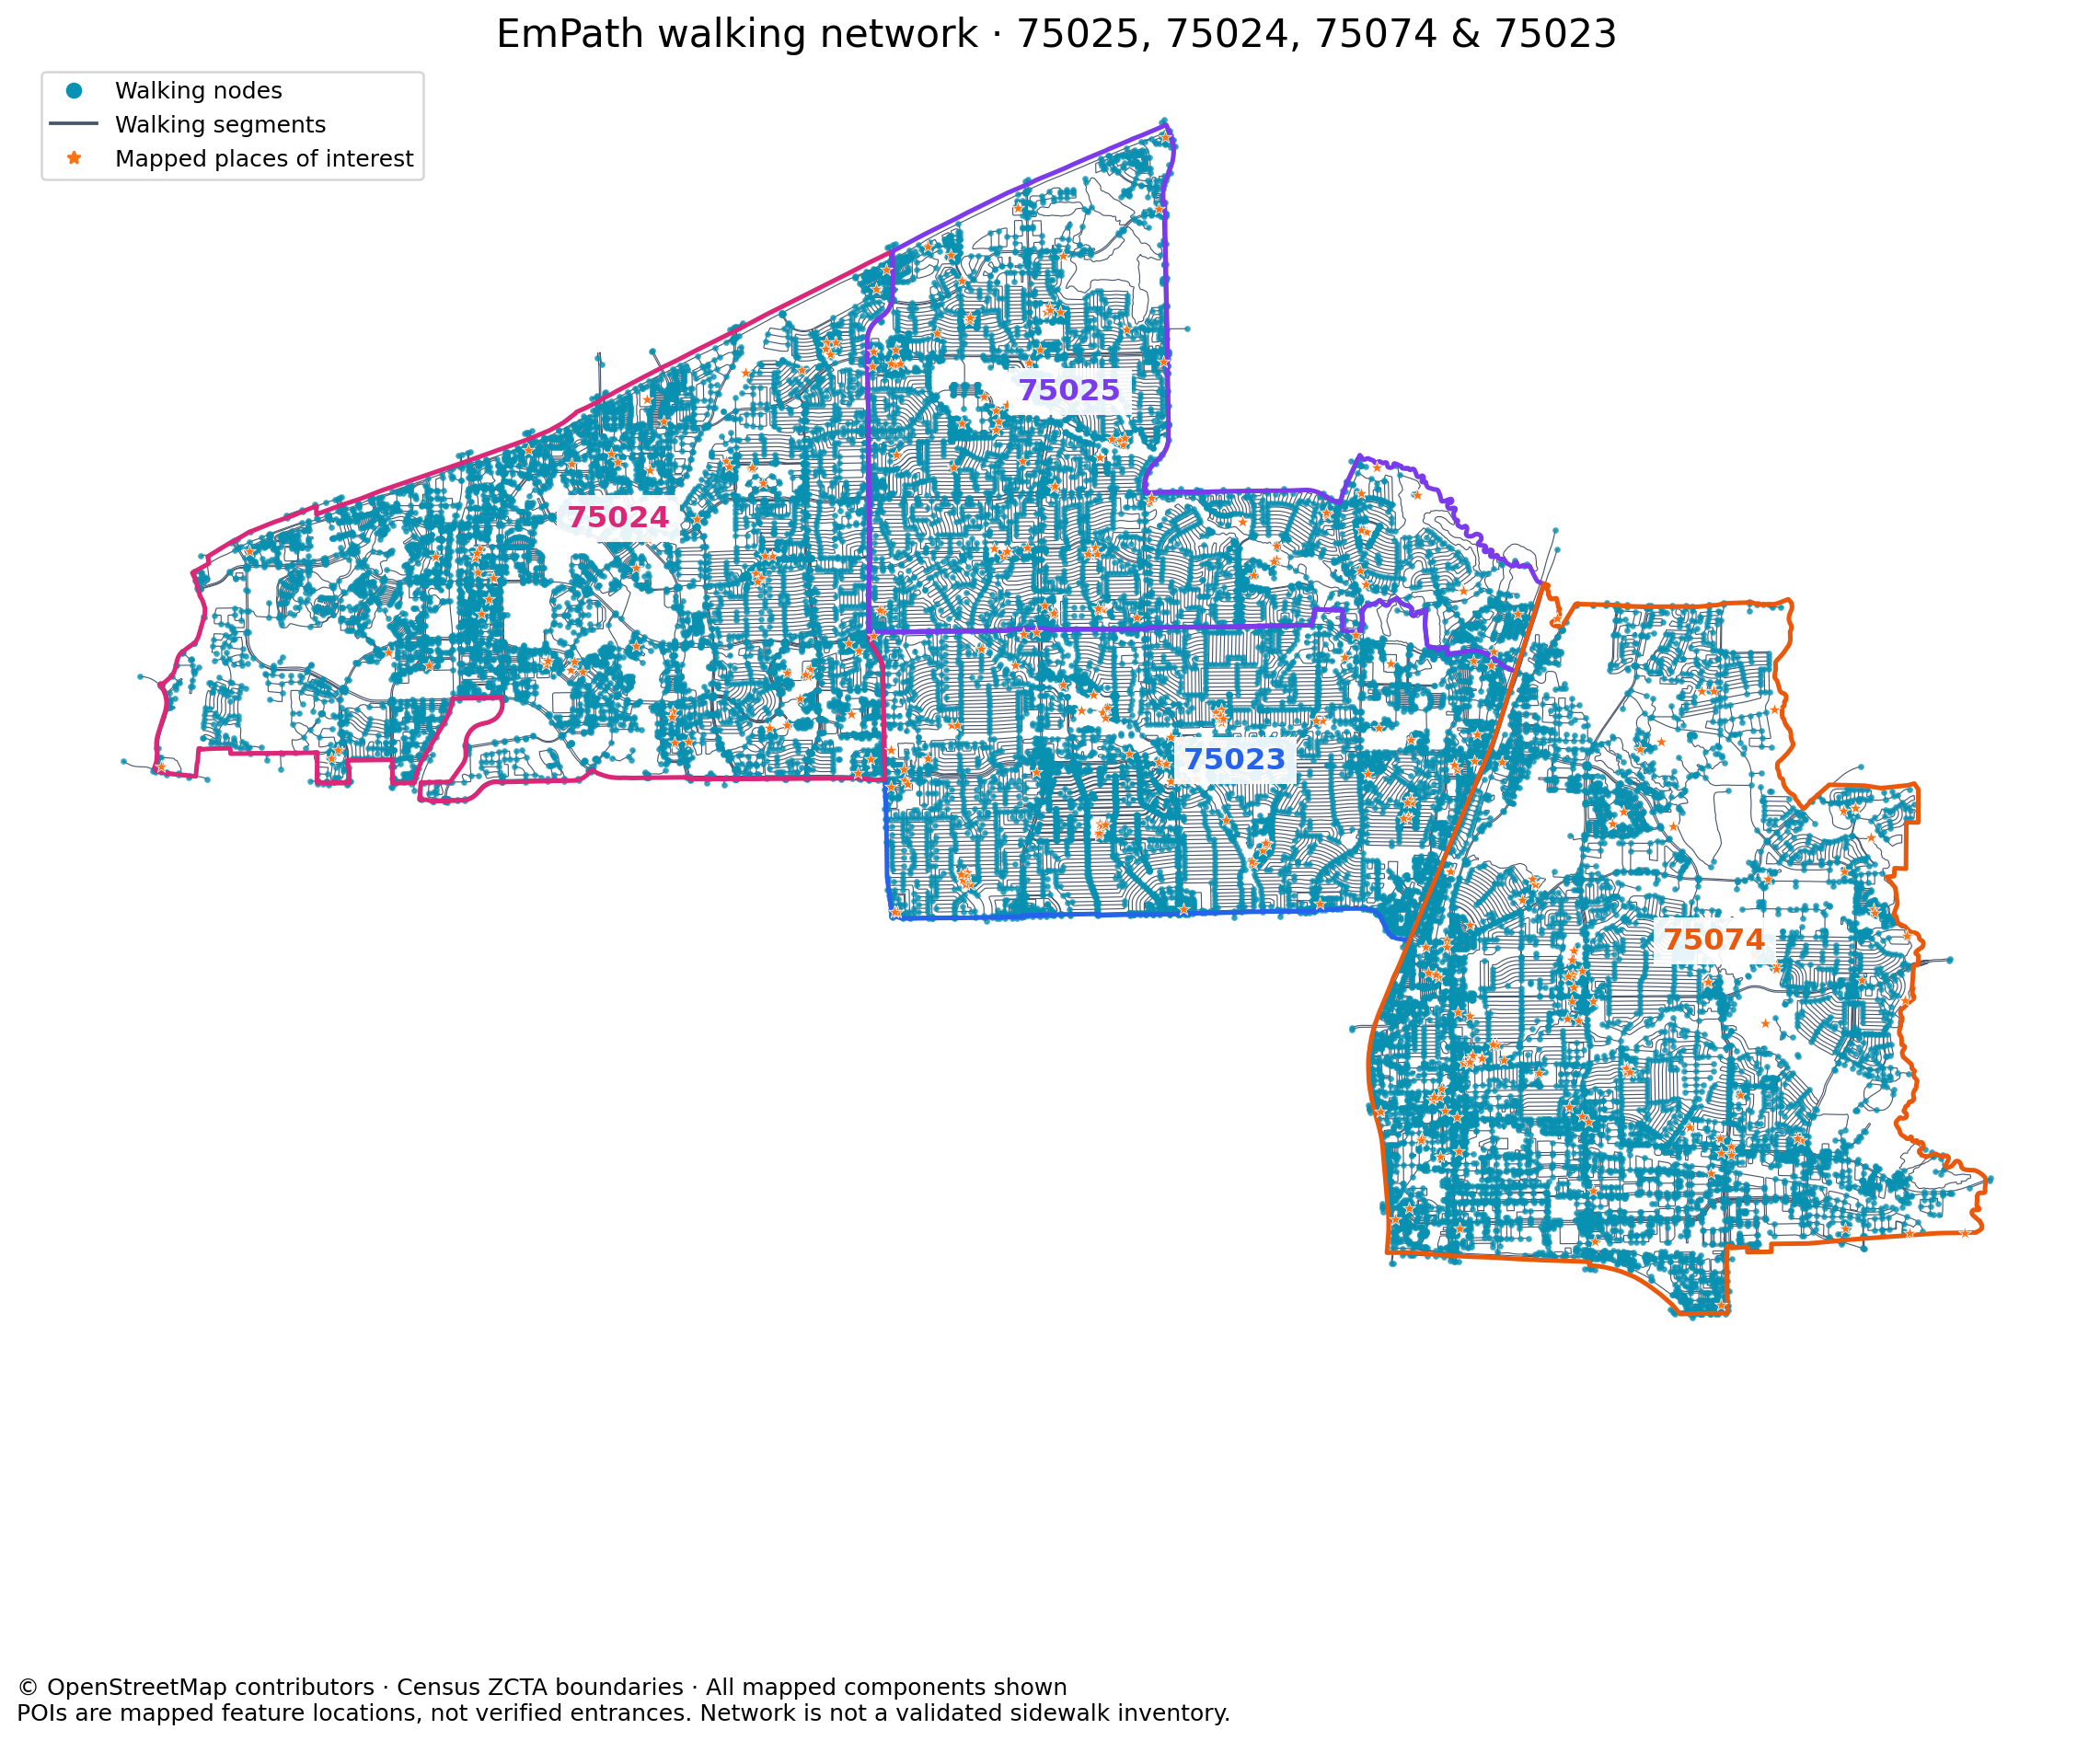

In [2]:
import json
import pandas as pd
from IPython.display import display, Image
summary = json.loads((OUTPUT / 'summary.json').read_text())
display(pd.DataFrame(summary['per_zcta']))
print(f"{summary['nodes']:,} nodes · {summary['directed_edges']:,} directed edges · {summary['component_count']:,} components")
print(f"{summary['poi_features']:,} mapped places of interest")
display(Image(filename=str(OUTPUT / 'walking_scope_map.png')))


In [3]:
# Open the interactive map in your browser for zoom, POI popups and layer toggles.
import webbrowser
webbrowser.open((OUTPUT / 'walking_scope_map.html').as_uri())


True

Outputs are in `output/four_zip_walking_network/`: interactive HTML, PNG, boundaries, POIs, node/edge tables, GeoPackage, full GraphML and a separate connected GraphML. Basemap tiles and map JavaScript require internet. Read `summary.json` for per-ZCTA node coverage and limitations. OSM walking data is a baseline; crossings, access and sidewalk completeness need validation against local data.